In [1]:
from time import time

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

categories = None


def size_mb(docs):
    return sum(len(s.encode("utf-8")) for s in docs) / 1e6


def load_dataset(verbose=False, remove=()):
    """Load and vectorize the 20 newsgroups dataset."""

    data_train = fetch_20newsgroups(
        subset="train",
        categories=categories,
        shuffle=True,
        random_state=42,
        remove=remove,
    )

    data_test = fetch_20newsgroups(
        subset="test",
        categories=categories,
        shuffle=True,
        random_state=42,
        remove=remove,
    )

    # order of labels in `target_names` can be different from `categories`
    target_names = data_train.target_names

    # split target in a training set and a test set
    y_train, y_test = data_train.target, data_test.target

    # Extracting features from the training data using a sparse vectorizer
    t0 = time()
    vectorizer = TfidfVectorizer(
        sublinear_tf=True, max_df=0.5, min_df=5, stop_words="english"
    )
    X_train = vectorizer.fit_transform(data_train.data)
    duration_train = time() - t0

    # Extracting features from the test data using the same vectorizer
    t0 = time()
    X_test = vectorizer.transform(data_test.data)
    duration_test = time() - t0

    feature_names = vectorizer.get_feature_names_out()

    # Feature type 1: raw word counts (no normalisation, no idf)
    counts_vectorizer = CountVectorizer(max_df=0.5, min_df=5, stop_words="english")
    counts_X_train = counts_vectorizer.fit_transform(data_train.data)
    counts_X_test = counts_vectorizer.transform(data_test.data)

    # Feature type 2: tf only (tf-idf with the idf part switched off).
    # sublinear_tf matches the tf-idf vectorizer above, so idf is the only difference.
    tf_vectorizer = TfidfVectorizer(
        use_idf=False, sublinear_tf=True, max_df=0.5, min_df=5, stop_words="english"
    )
    tf_X_train = tf_vectorizer.fit_transform(data_train.data)
    tf_X_test = tf_vectorizer.transform(data_test.data)

    # Feature type 3 (tf-idf) is X_train / X_test, built above.

    if verbose:
        # compute size of loaded data
        data_train_size_mb = size_mb(data_train.data)
        data_test_size_mb = size_mb(data_test.data)

        print(
            f"{len(data_train.data)} documents - "
            f"{data_train_size_mb:.2f}MB (training set)"
        )
        print(f"{len(data_test.data)} documents - {data_test_size_mb:.2f}MB (test set)")
        print(f"{len(target_names)} categories")
        print(
            f"vectorize training done in {duration_train:.3f}s "
            f"at {data_train_size_mb / duration_train:.3f}MB/s"
        )
        print(f"n_samples: {X_train.shape[0]}, n_features: {X_train.shape[1]}")
        print(
            f"vectorize testing done in {duration_test:.3f}s "
            f"at {data_test_size_mb / duration_test:.3f}MB/s"
        )
        print(f"n_samples: {X_test.shape[0]}, n_features: {X_test.shape[1]}")

    return (
        X_train,
        X_test,
        y_train,
        y_test,
        feature_names,
        target_names,
        tf_X_train,
        tf_X_test,
        counts_X_train,
        counts_X_test,
    )

In [2]:
X_train, X_test, y_train, y_test, feature_names, target_names, *_ = load_dataset(verbose=True)

from sklearn.linear_model import RidgeClassifier

clf = RidgeClassifier(tol=1e-2, solver="sparse_cg")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

11314 documents - 22.05MB (training set)
7532 documents - 13.80MB (test set)
20 categories
vectorize training done in 1.846s at 11.948MB/s
n_samples: 11314, n_features: 25631
vectorize testing done in 0.963s at 14.331MB/s
n_samples: 7532, n_features: 25631


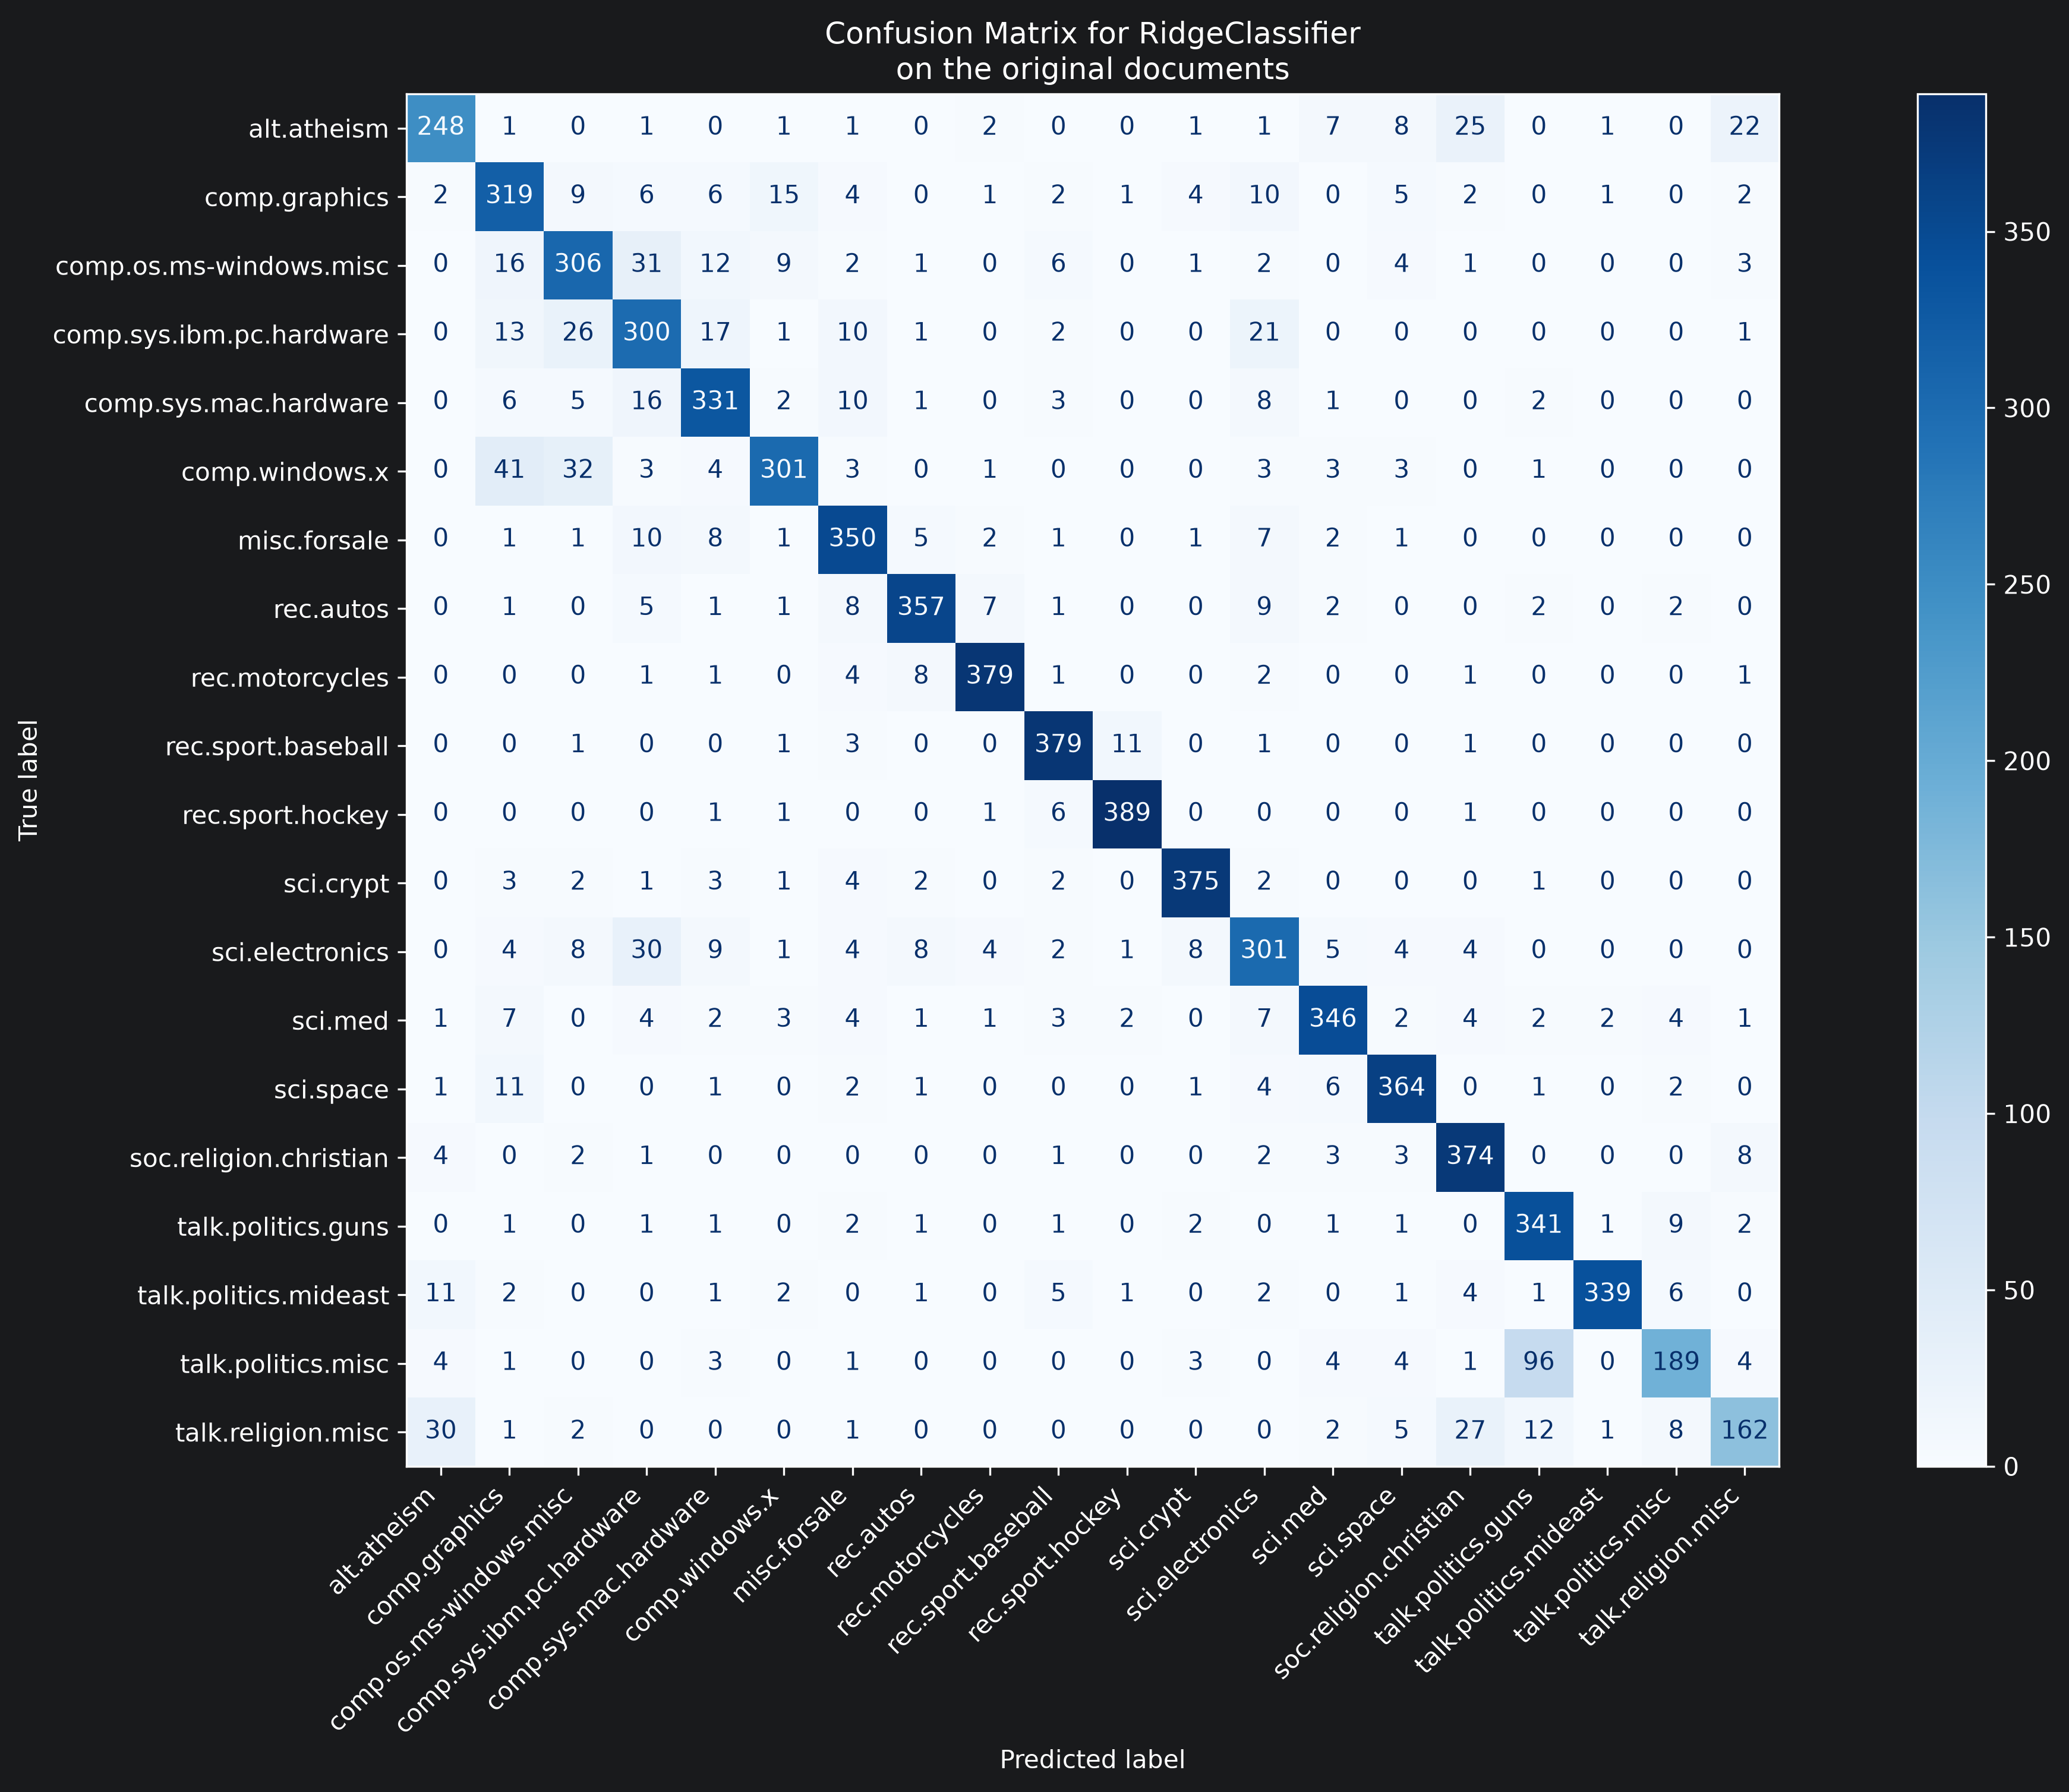

In [3]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(20, 10))
fig.set_dpi(300)
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap=plt.cm.Blues)
ax.xaxis.set_ticklabels(target_names, rotation=45, ha="right")
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(
    f"Confusion Matrix for {clf.__class__.__name__}\non the original documents"
)

top 5 keywords per class:
  alt.atheism comp.graphics comp.os.ms-windows.misc comp.sys.ibm.pc.hardware  \
0       keith      graphics                 windows                     help   
1         god         image                    file                   thanks   
2    atheists          need                     win                      com   
3     article      computer                     use                       pc   
4     atheism            3d                  driver                     card   

  comp.sys.mac.hardware comp.windows.x  misc.forsale rec.autos  \
0                   mac         window          sale       car   
1                 apple          motif  distribution       com   
2                    se         server        wanted      cars   
3                  does            sun           new   article   
4                 drive            mit         offer       usa   

  rec.motorcycles rec.sport.baseball rec.sport.hockey   sci.crypt  \
0             dod          

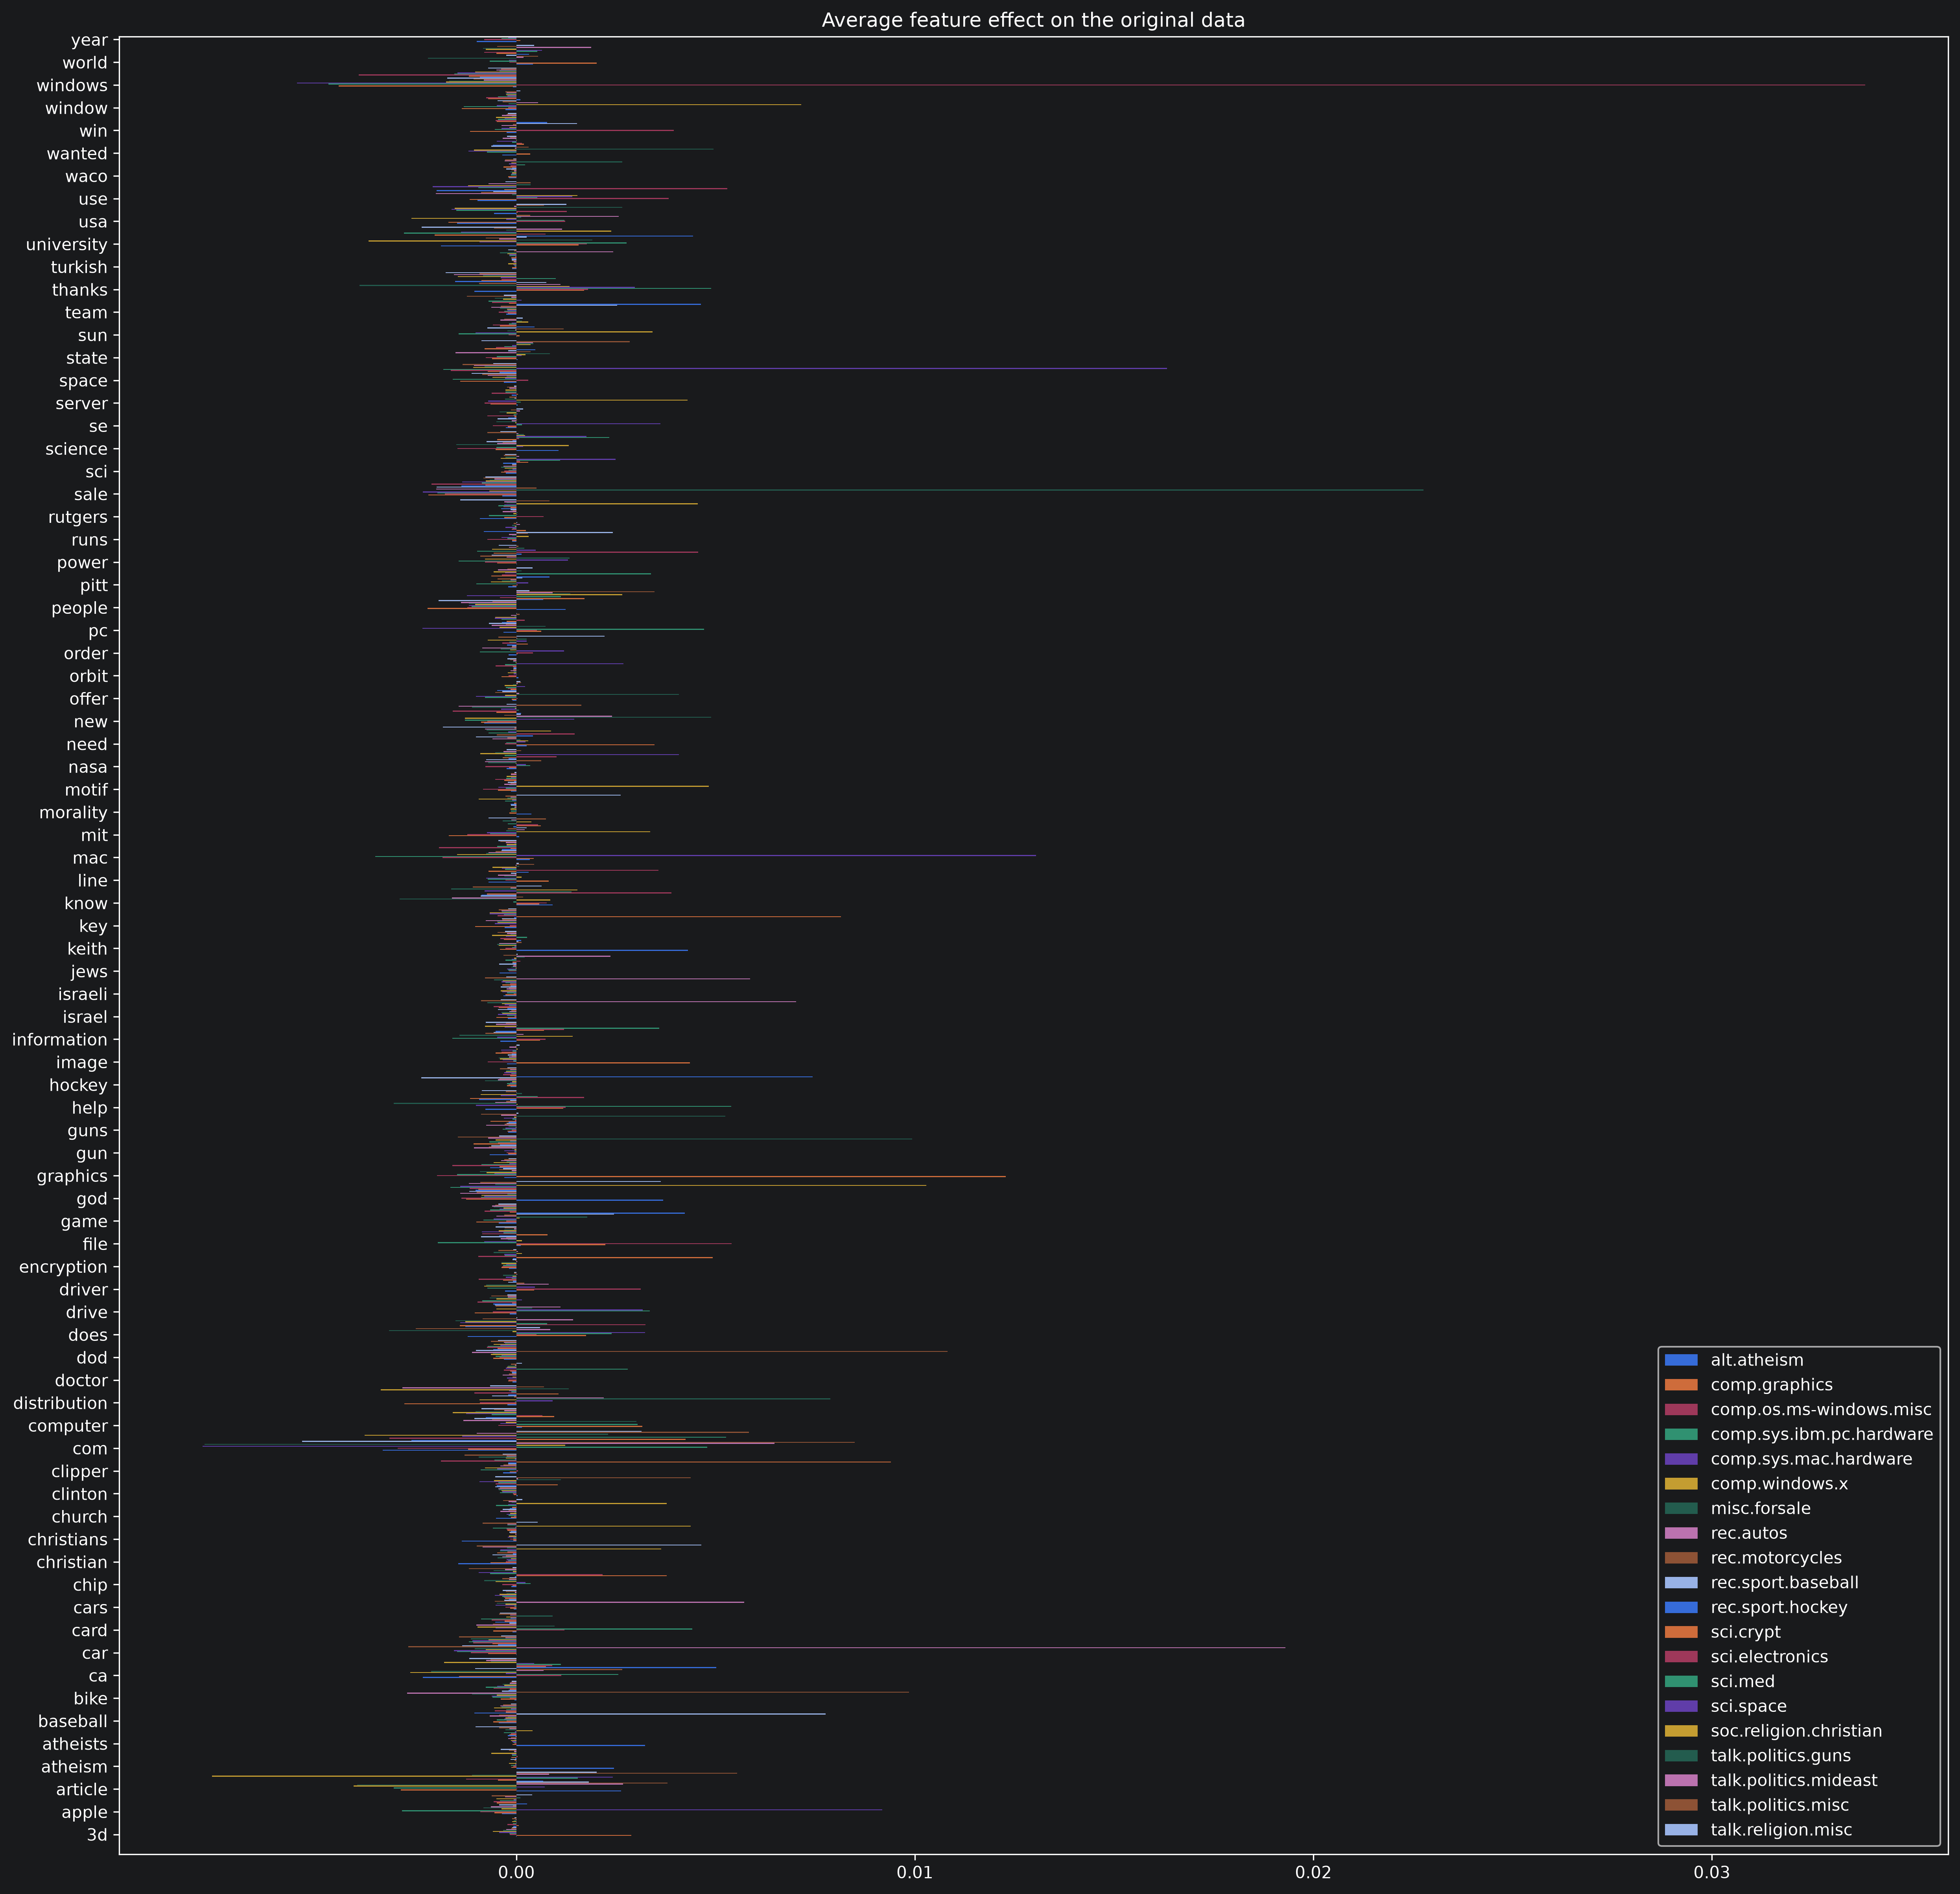

In [4]:
import numpy as np
import pandas as pd


def plot_feature_effects():
    # learned coefficients weighted by frequency of appearance
    average_feature_effects = clf.coef_ * np.asarray(X_train.mean(axis=0)).ravel()

    for i, label in enumerate(target_names):
        top5 = np.argsort(average_feature_effects[i])[-5:][::-1]
        if i == 0:
            top = pd.DataFrame(feature_names[top5], columns=[label])
            top_indices = top5
        else:
            top[label] = feature_names[top5]
            top_indices = np.concatenate((top_indices, top5), axis=None)
    top_indices = np.unique(top_indices)
    predictive_words = feature_names[top_indices]

    # plot feature effects
    bar_size = 0.25
    padding = 0.75
    y_locs = np.arange(len(top_indices)) * (20 * bar_size + padding)

    fig, ax = plt.subplots(figsize=(20, 20))
    fig.set_dpi(300)
    for i, label in enumerate(target_names):
        ax.barh(
            y_locs + (i - 2) * bar_size,
            average_feature_effects[i, top_indices],
            height=bar_size,
            label=label,
        )
    ax.set(
        yticks=y_locs,
        yticklabels=predictive_words,
        ylim=[
            0 - 20 * bar_size,
            len(top_indices) * (20 * bar_size + padding) - 20 * bar_size,
        ],
    )
    ax.legend(loc="lower right")

    print("top 5 keywords per class:")
    print(top)

    return ax


_ = plot_feature_effects().set_title("Average feature effect on the original data")

In [5]:
data_train = fetch_20newsgroups(
    subset="train", categories=categories, shuffle=True, random_state=42
)

for doc in data_train.data:
    if "caltech" in doc:
        print(doc)
        break

From: keith@cco.caltech.edu (Keith Allan Schneider)
Subject: Re: <<Pompous ass
Organization: California Institute of Technology, Pasadena
Lines: 16
NNTP-Posting-Host: punisher.caltech.edu

livesey@solntze.wpd.sgi.com (Jon Livesey) writes:

[...]
>>The "`little' things" above were in reference to Germany, clearly.  People
>>said that there were similar things in Germany, but no one could name any.
>That's not true.  I gave you two examples.  One was the rather
>pevasive anti-semitism in German Christianity well before Hitler
>arrived.  The other was the system of social ranks that were used
>in Imperail Germany and Austria to distinguish Jews from the rest 
>of the population.

These don't seem like "little things" to me.  At least, they are orders
worse than the motto.  Do you think that the motto is a "little thing"
that will lead to worse things?

keith



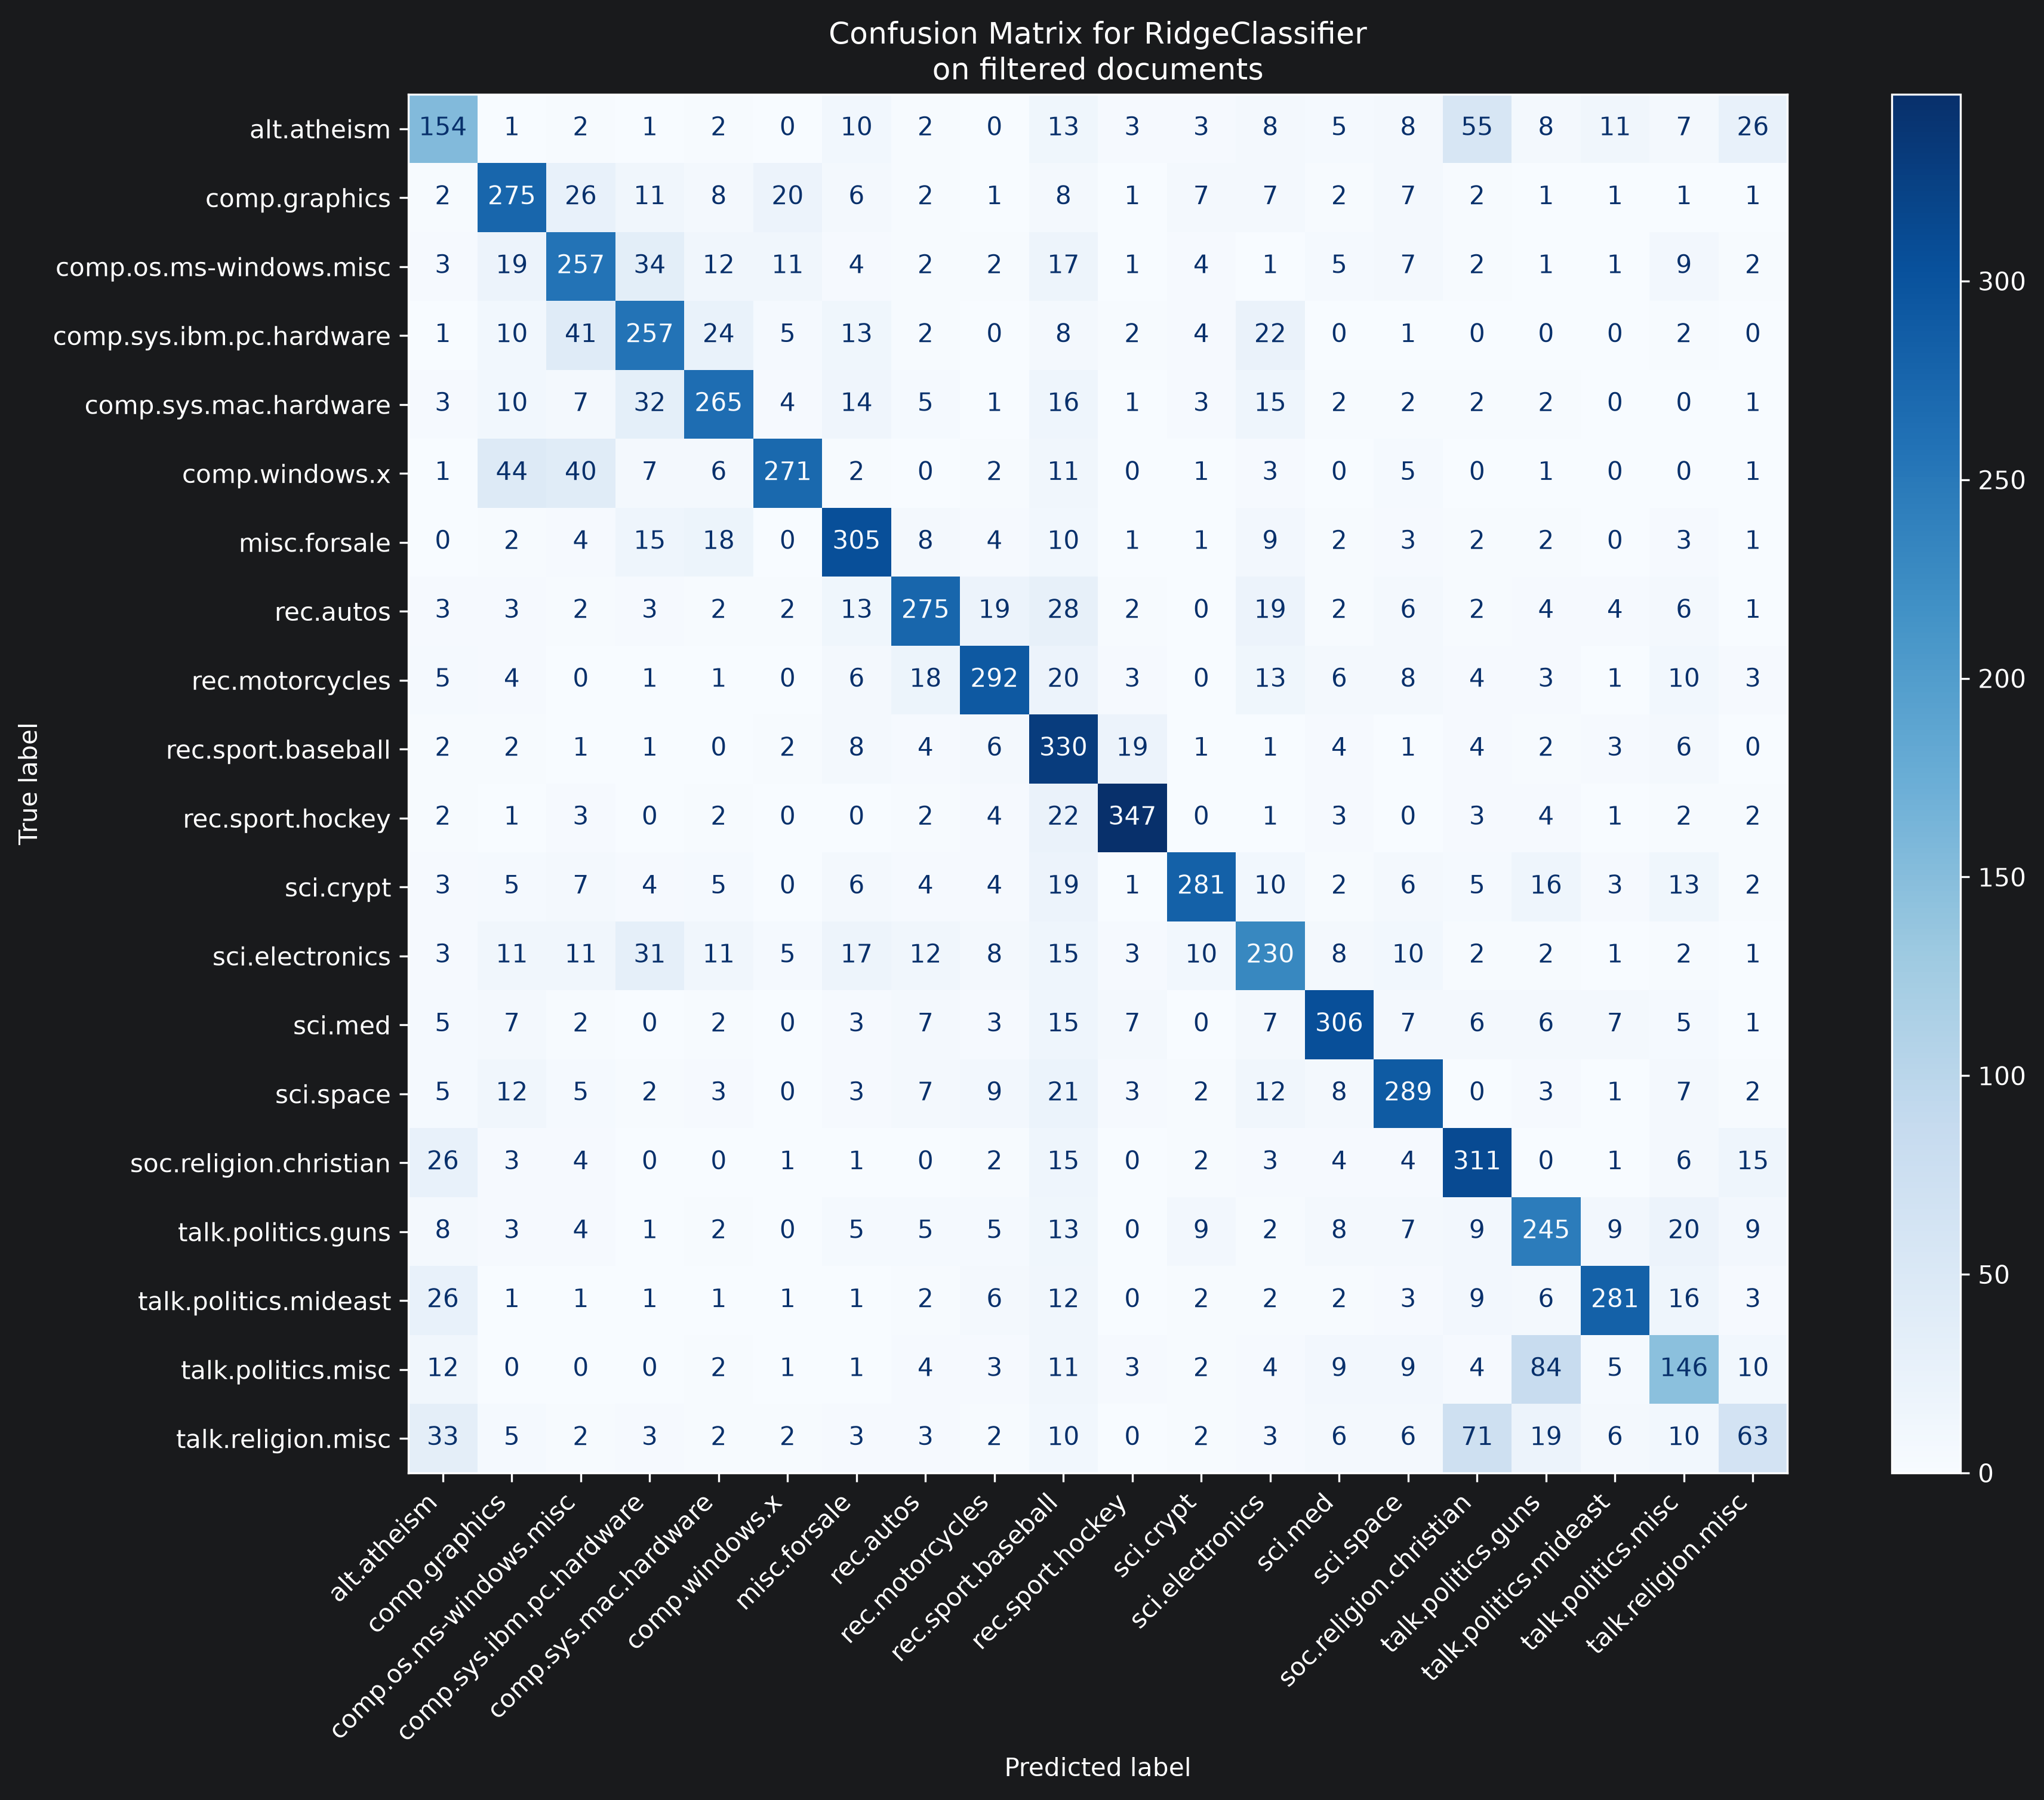

In [6]:
(
    X_train,
    X_test,
    y_train,
    y_test,
    feature_names,
    target_names,
    tf_X_train,
    tf_X_test,
    counts_X_train,
    counts_X_test,
) = load_dataset(remove=("headers", "footers", "quotes"))

# the tf-idf matrices are X_train / X_test; give them an explicit name too
tfidf_X_train, tfidf_X_test = X_train, X_test

clf = RidgeClassifier(tol=1e-2, solver="sparse_cg")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

fig, ax = plt.subplots(figsize=(15, 10))
fig.set_dpi(300)
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap= plt.cm.Blues)
ax.xaxis.set_ticklabels(target_names, rotation=45, ha="right")
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(
    f"Confusion Matrix for {clf.__class__.__name__}\non filtered documents"
)

top 5 keywords per class:
  alt.atheism comp.graphics comp.os.ms-windows.misc comp.sys.ibm.pc.hardware  \
0         don      graphics                 windows                       pc   
1    religion         image                    file                     card   
2        just         files                     use                     help   
3         god          need                 problem               controller   
4     atheism       program                    mail                      bus   

  comp.sys.mac.hardware comp.windows.x misc.forsale rec.autos rec.motorcycles  \
0                   mac         window         sale       car            bike   
1                 apple         server        offer      cars             dod   
2                 drive          motif          new       new            ride   
3                  does            use         sell    dealer           bikes   
4               problem             hi     shipping       oil             edu   

  rec.

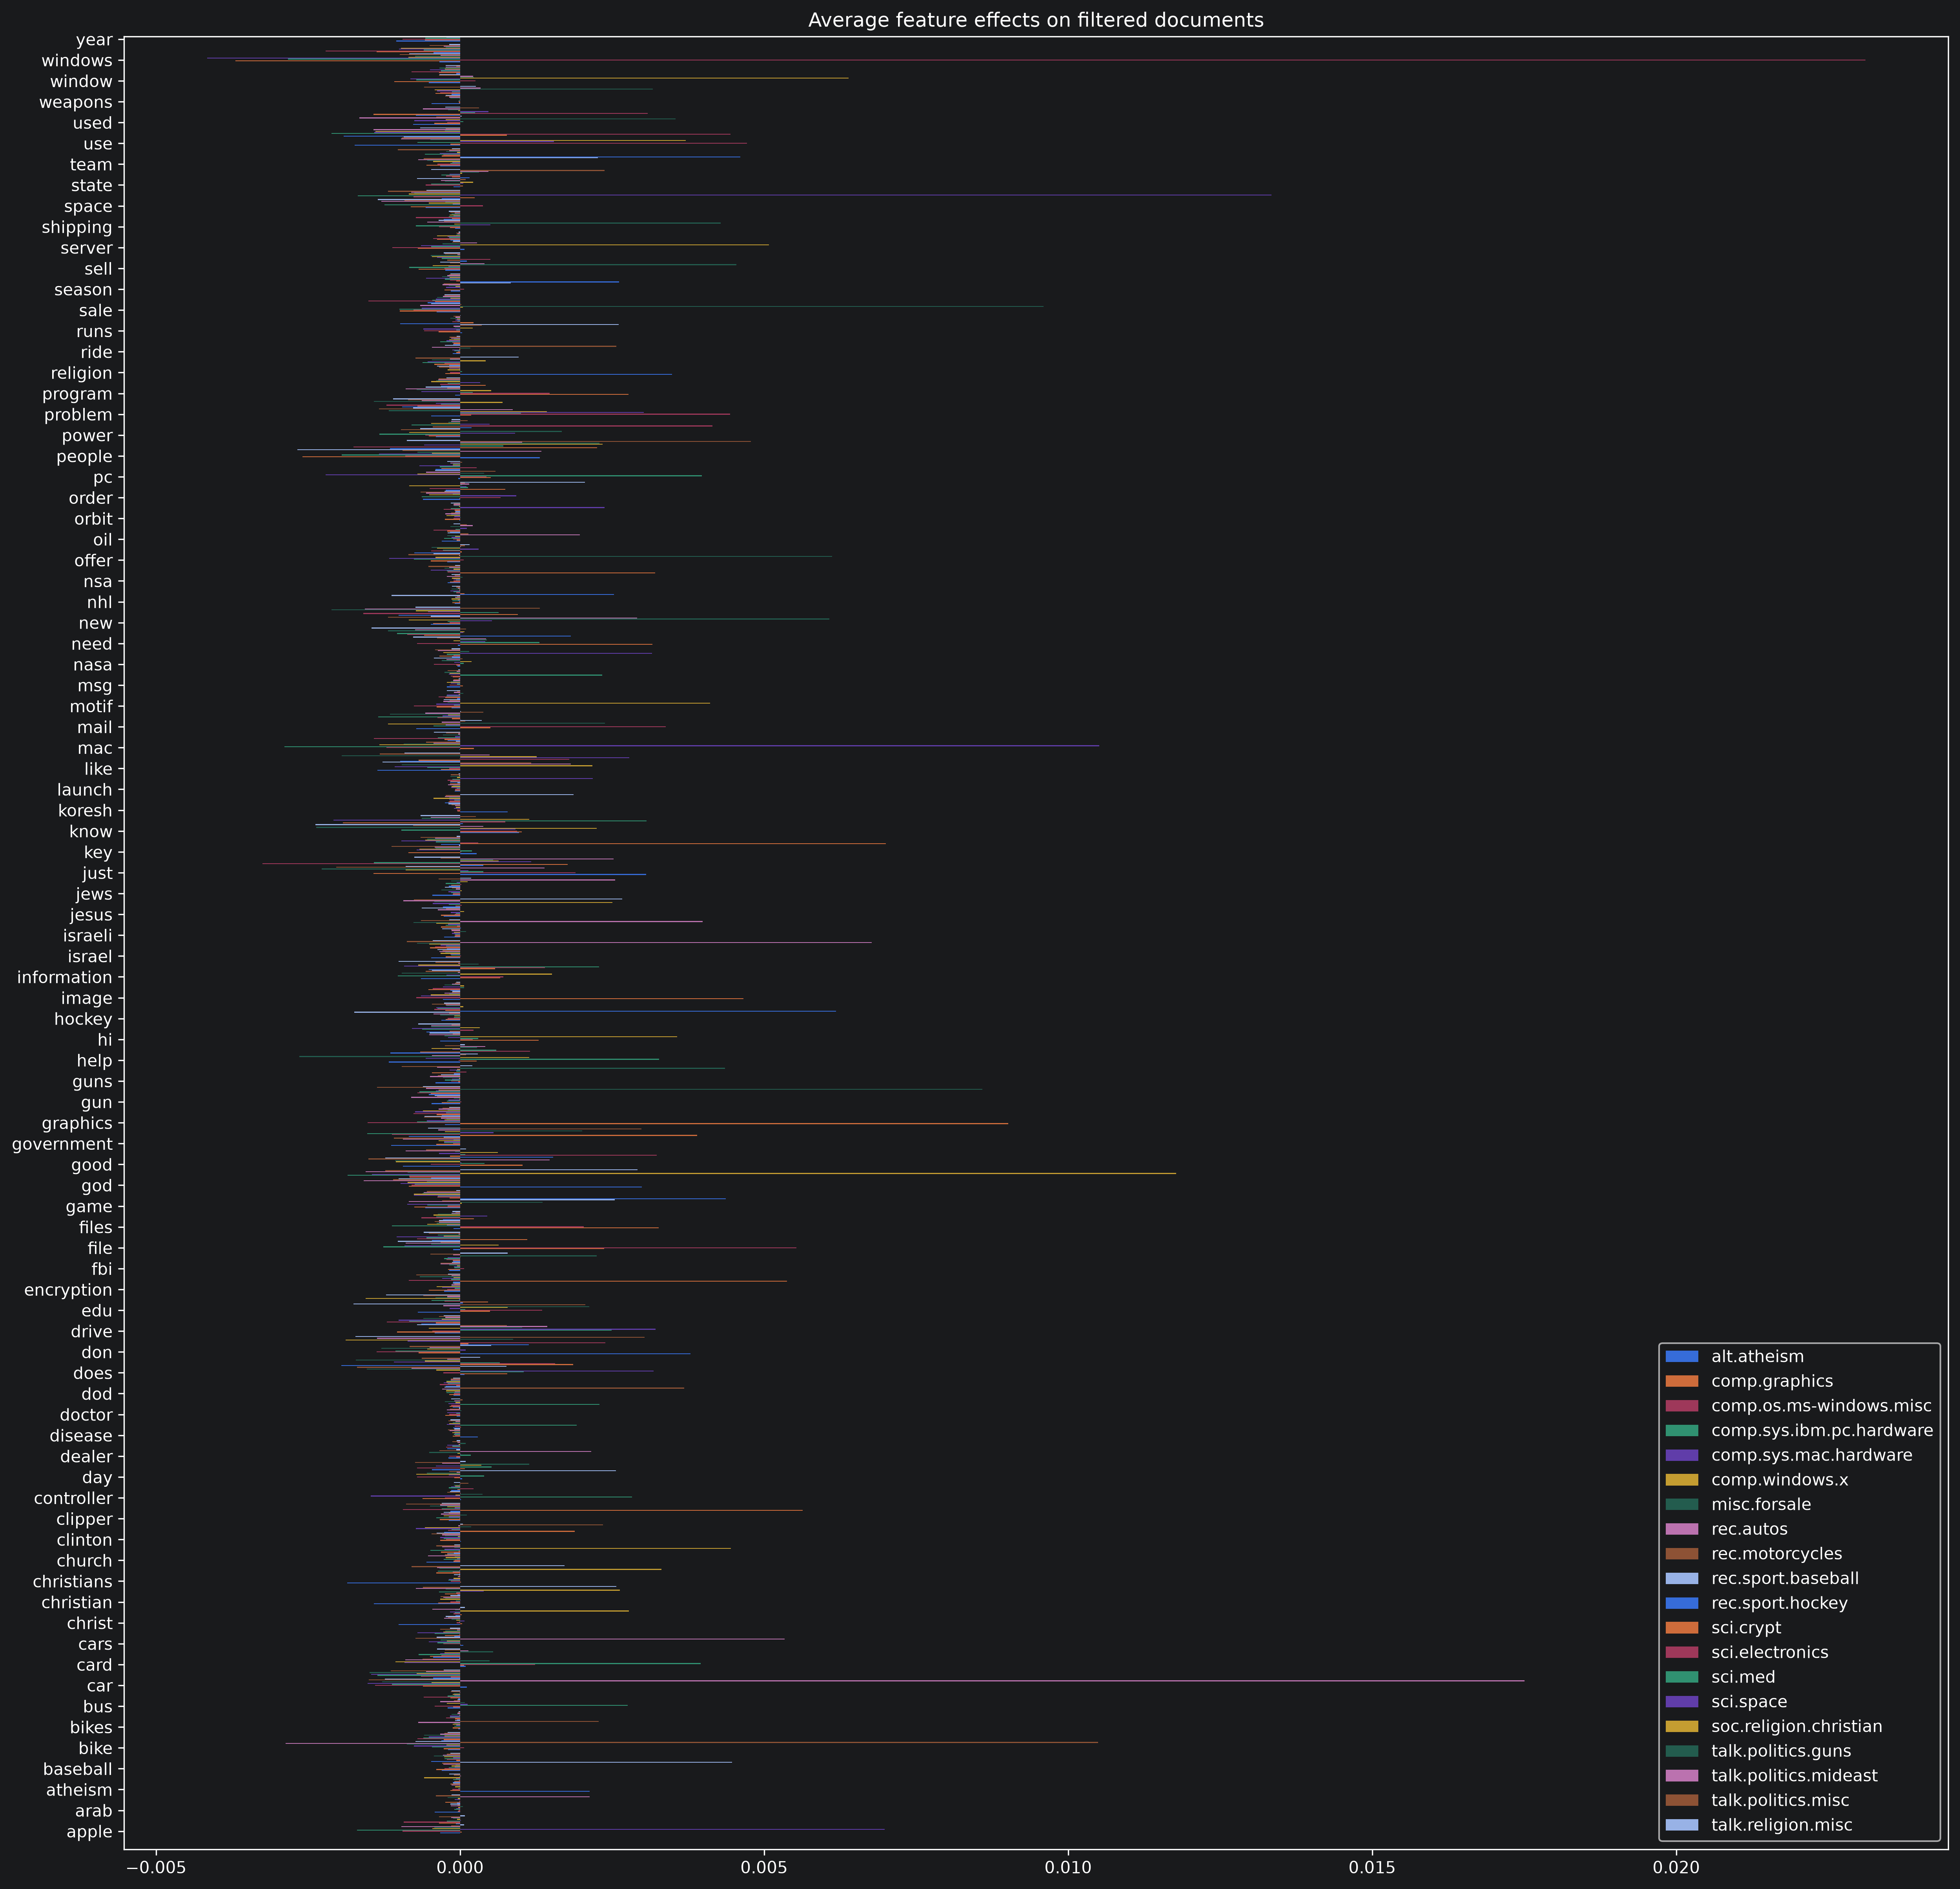

In [7]:
_ = plot_feature_effects().set_title("Average feature effects on filtered documents")

In [8]:
from sklearn import metrics
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.utils.extmath import density


def benchmark(clf, X_train, X_test, y_train, y_test, custom_name=False):
    """Train clf on (X_train, y_train) and evaluate it on (X_test, y_test).
    Returns: name, accuracy, train_time, test_time, precision, recall, f1 (macro-averaged)."""
    print("_" * 80)
    print("Training: ")
    print(clf)
    t0 = time()
    clf.fit(X_train, y_train)
    train_time = time() - t0
    print(f"train time: {train_time:.3}s")

    t0 = time()
    pred = clf.predict(X_test)
    test_time = time() - t0
    print(f"test time:  {test_time:.3}s")

    score = metrics.accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average="macro", zero_division=0)
    recall = recall_score(y_test, pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, pred, average="macro", zero_division=0)
    print(f"accuracy:   {score:.3}")
    print(f"precision:  {prec:.3}")
    print(f"recall:     {recall:.3}")
    print(f"f1:         {f1:.3}")

    if hasattr(clf, "coef_"):
        print(f"dimensionality: {clf.coef_.shape[1]}")
        print(f"density: {density(clf.coef_)}")
        print()

    print()
    clf_descr = str(custom_name) if custom_name else clf.__class__.__name__
    return clf_descr, score, train_time, test_time, prec, recall, f1

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC

# Quick look: the three main classifiers on the tf-idf features
results = []
for clf, name in (
    (LogisticRegression(C=5, max_iter=1000), "Logistic Regression"),
    # L2 penalty Linear SVC
    (LinearSVC(C=0.1, dual=False, max_iter=1000), "Linear SVC"),
    # Sparse naive Bayes classifier
    (ComplementNB(alpha=0.1), "Complement naive Bayes"),
):
    print("=" * 80)
    print(name)
    results.append(benchmark(clf, X_train, X_test, y_train, y_test, name))

Logistic Regression
________________________________________________________________________________
Training: 
LogisticRegression(C=5, max_iter=1000)
train time: 3.48s
test time:  0.00627s
accuracy:   0.683
precision:  0.682
recall:     0.672
f1:         0.673
dimensionality: 17797
density: 1.0


Linear SVC
________________________________________________________________________________
Training: 
LinearSVC(C=0.1, dual=False)
train time: 1.39s
test time:  0.00689s
accuracy:   0.695
precision:  0.693
recall:     0.68
f1:         0.678
dimensionality: 17797
density: 1.0


Complement naive Bayes
________________________________________________________________________________
Training: 
ComplementNB(alpha=0.1)
train time: 0.0169s
test time:  0.00673s
accuracy:   0.694
precision:  0.688
recall:     0.678
f1:         0.674



In [26]:
df = pd.DataFrame(
    results,
    columns=["Classifier", "Accuracy", "Train Time", "Test Time", "Precision", "Recall", "F1"],
)
display(df.set_index("Classifier")[[ "Precision", "Recall", "F1"]].round(3))

,Precision,Recall,F1
Classifier,,,
Logistic Regression,0.682,0.672,0.673
Linear SVC,0.693,0.680,0.678
Complement naive Bayes,0.688,0.678,0.674


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.svm import LinearSVC


feature_sets = {
    "counts": (counts_X_train, counts_X_test),
    "tf": (tf_X_train, tf_X_test),
    "tf-idf": (tfidf_X_train, tfidf_X_test),
}


def make_classifiers():
    """Fresh, untrained classifiers (so nothing is reused between feature types)."""
    return (
        (LogisticRegression(C=5, max_iter=1000), "Logistic Regression"),
        (RidgeClassifier(alpha=1.0, solver="sparse_cg"), "Ridge Classifier"),
        (
            KNeighborsClassifier(n_neighbors=15, algorithm="brute", metric="cosine"),
            "kNN",
        ),
        (RandomForestClassifier(), "Random Forest"),
        # L2 penalty Linear SVC
        (LinearSVC(C=0.1, dual=False, max_iter=1000), "Linear SVC"),
        # L2 penalty Linear SGD
        (
            SGDClassifier(
                loss="log_loss", alpha=1e-4, n_iter_no_change=3, early_stopping=True
            ),
            "log-loss SGD",
        ),
        # NearestCentroid
        (NearestCentroid(), "NearestCentroid"),
        # Sparse naive Bayes classifier
        (ComplementNB(alpha=0.1), "Complement naive Bayes"),
    )


# Benchmark run 1: full per-model printout, every classifier on every feature type
results_all = []
for feature_name, (Xtr, Xte) in feature_sets.items():
    print("#" * 80)
    print(f"FEATURES: {feature_name}")
    for clf, name in make_classifiers():
        print("=" * 80)
        print(name)
        clf_descr, score, train_time, test_time, precision, recall, f1 = benchmark(clf, Xtr, Xte, y_train, y_test, name)
        results_all.append(
            {
                "features": feature_name,
                "classifier": clf_descr,
                "accuracy": score,
                "train_time": train_time,
                "test_time": test_time,
                "Precision": precision,
                "Recall": recall,
                "F1": f1,
            }
        )


################################################################################
FEATURES: counts
Logistic Regression
________________________________________________________________________________
Training: 
LogisticRegression(C=5, max_iter=1000)
train time: 7.03s
test time:  0.00654s
accuracy:   0.601
precision:  0.601
recall:     0.591
f1:         0.593
dimensionality: 17797
density: 1.0


Ridge Classifier
________________________________________________________________________________
Training: 
RidgeClassifier(solver='sparse_cg')
train time: 99.3s
test time:  0.0123s
accuracy:   0.443
precision:  0.451
recall:     0.436
f1:         0.437
dimensionality: 17797
density: 1.0


kNN
________________________________________________________________________________
Training: 
KNeighborsClassifier(algorithm='brute', metric='cosine', n_neighbors=15)
train time: 0.00289s
test time:  2.02s
accuracy:   0.514
precision:  0.533
recall:     0.505
f1:         0.505

Random Forest
________________

D:\Text-Mining\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


train time: 82.4s
test time:  0.00661s
accuracy:   0.627
precision:  0.623
recall:     0.616
f1:         0.617
dimensionality: 17797
density: 1.0


log-loss SGD
________________________________________________________________________________
Training: 
SGDClassifier(early_stopping=True, loss='log_loss', n_iter_no_change=3)
train time: 0.406s
test time:  0.00736s
accuracy:   0.581
precision:  0.594
recall:     0.568
f1:         0.569
dimensionality: 17797
density: 0.9950300612462775


NearestCentroid
________________________________________________________________________________
Training: 
NearestCentroid()
train time: 3.44s
test time:  0.0909s
accuracy:   0.315
precision:  0.543
recall:     0.309
f1:         0.338

Complement naive Bayes
________________________________________________________________________________
Training: 
ComplementNB(alpha=0.1)
train time: 0.0236s
test time:  0.0281s
accuracy:   0.656
precision:  0.65
recall:     0.64
f1:         0.626

########################

In [12]:
# Benchmark run 2: compact summary of the results above (no retraining)
summary = pd.DataFrame(results_all)

for metric in ["accuracy", "Precision", "Recall", "F1"]:
    print(f"Test {metric} (rows: classifier, columns: feature type)")
    print(summary.pivot(index="classifier", columns="features", values=metric).round(3))
    print()
print("Training time in seconds")
print(summary.pivot(index="classifier", columns="features", values="train_time").round(2))
print()

# Report table: 3 classifiers x 3 feature types, macro Precision / Recall / F1
main = ["Logistic Regression", "Linear SVC", "Complement naive Bayes"]
report_table = (
    summary[summary["classifier"].isin(main)]
    .pivot(index="classifier", columns="features", values=["Precision", "Recall", "F1"])
    .round(3)
)
print("Report table (macro-averaged):")
print(report_table.to_string())
print()
summary.to_csv("classifier_feature_results.csv", index=False)   # stored results

for metric in ["accuracy", "F1"]:
    best = summary.loc[summary[metric].idxmax()]
    print(
        f"Best combination by test {metric}: {best['classifier']} + {best['features']} "
        f"(accuracy {best['accuracy']:.3f}, F1 {best['F1']:.3f}, train time {best['train_time']:.2f}s)"
    )
print()
print("Top 5 combinations (by F1):")
cols = ["features", "classifier", "accuracy", "Precision", "Recall", "F1", "train_time"]
print(summary.sort_values("F1", ascending=False)[cols].head(5).round(3).to_string(index=False))

Test accuracy (rows: classifier, columns: feature type)
features                counts     tf  tf-idf
classifier                                   
Complement naive Bayes   0.656  0.699   0.694
Linear SVC               0.627  0.669   0.695
Logistic Regression      0.601  0.655   0.683
NearestCentroid          0.315  0.577   0.639
Random Forest            0.599  0.604   0.610
Ridge Classifier         0.443  0.680   0.688
kNN                      0.514  0.540   0.643
log-loss SGD             0.581  0.647   0.687

Test Precision (rows: classifier, columns: feature type)
features                counts     tf  tf-idf
classifier                                   
Complement naive Bayes   0.650  0.695   0.688
Linear SVC               0.623  0.665   0.693
Logistic Regression      0.601  0.654   0.682
NearestCentroid          0.543  0.624   0.690
Random Forest            0.597  0.595   0.603
Ridge Classifier         0.451  0.678   0.685
kNN                      0.533  0.562   0.651
log-loss SGD

# We chose tf-idf Complement NB for task 4

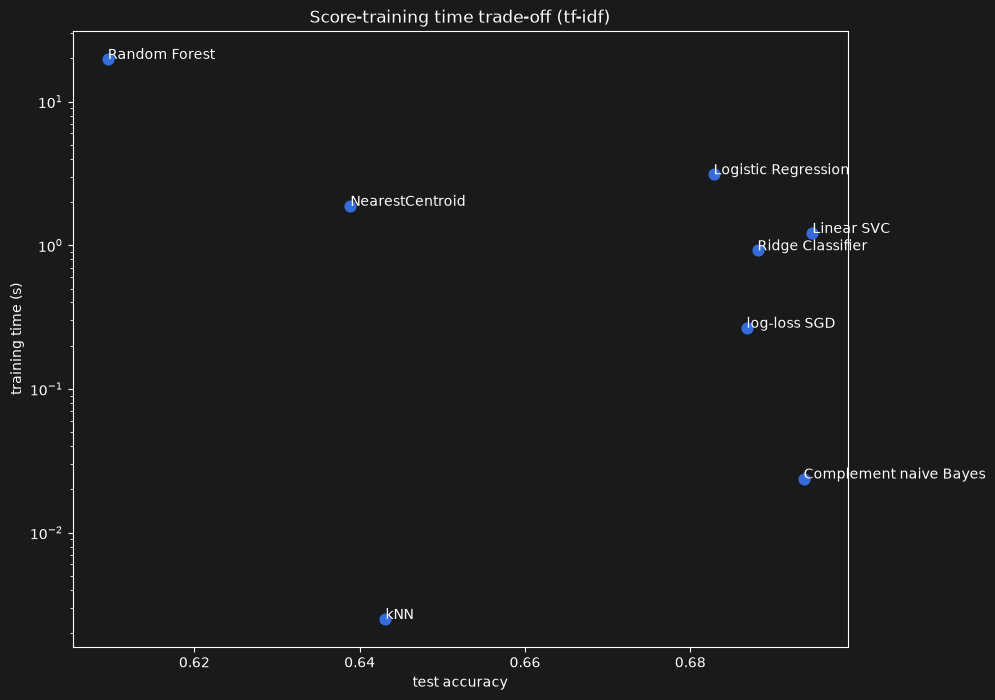

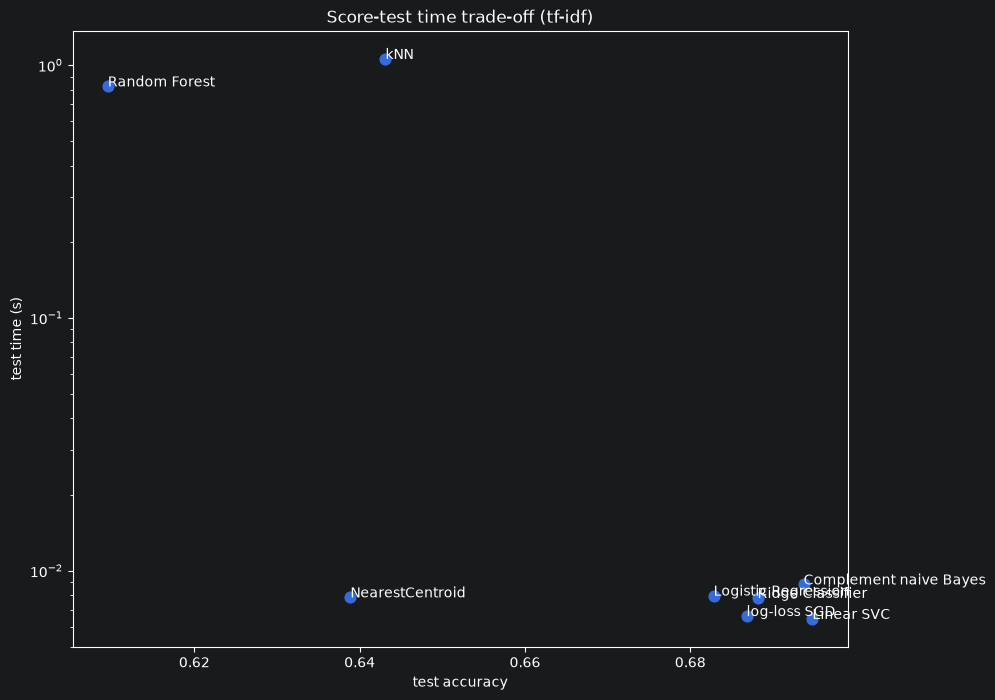

In [13]:
# Trade-off plots for the tf-idf features (as in the original tutorial)
tfidf_res = summary[summary["features"] == "tf-idf"]
clf_names = tfidf_res["classifier"].tolist()
score = tfidf_res["accuracy"].to_numpy()
training_time = tfidf_res["train_time"].to_numpy()
test_time = tfidf_res["test_time"].to_numpy()

fig, ax1 = plt.subplots(figsize=(10, 8))
ax1.scatter(score, training_time, s=60)
ax1.set(
    title="Score-training time trade-off (tf-idf)",
    yscale="log",
    xlabel="test accuracy",
    ylabel="training time (s)",
)
fig, ax2 = plt.subplots(figsize=(10, 8))
ax2.scatter(score, test_time, s=60)
ax2.set(
    title="Score-test time trade-off (tf-idf)",
    yscale="log",
    xlabel="test accuracy",
    ylabel="test time (s)",
)

for i, txt in enumerate(clf_names):
    ax1.annotate(txt, (score[i], training_time[i]))
    ax2.annotate(txt, (score[i], test_time[i]))


## Vectorizer parameter grid (tf-idf + Complement naive Bayes)

Every combination of lowercasing, stop words, analyzer/n-gram range and `max_features` is tried.
Combinations are compared on a **validation split of the training data**; the test set is used
only once, for the winning combination.

In [14]:
import itertools

from sklearn.model_selection import train_test_split


raw_train = fetch_20newsgroups(
    subset="train", shuffle=True, random_state=42,
    remove=("headers", "footers", "quotes"),
)
raw_test = fetch_20newsgroups(
    subset="test", shuffle=True, random_state=42,
    remove=("headers", "footers", "quotes"),
)


texts_fit, texts_val, y_fit, y_val = train_test_split(
    raw_train.data, raw_train.target,
    test_size=0.2, stratify=raw_train.target, random_state=42,
)


lowercase_values = [True, False]
stop_words_values = [None, "english"]
analyzer_ngram_values = [
    ("word", (1, 1)),
    ("word", (1, 2)),
    ("char_wb", (3, 5)),
]
max_features_values = [1000, 5000, 20000, None]


param_combinations = []
for lowercase, stop_words, (analyzer, ngram_range), max_features in itertools.product(
    lowercase_values, stop_words_values, analyzer_ngram_values, max_features_values
):

    if analyzer != "word" and stop_words is not None:
        continue
    param_combinations.append(
        {
            "lowercase": lowercase,
            "stop_words": stop_words,
            "analyzer": analyzer,
            "ngram_range": ngram_range,
            "max_features": max_features,
        }
    )

print(len(param_combinations), "combinations")

40 combinations


In [15]:
def run_vectorizer_experiments(param_combinations, train_texts, train_y, eval_texts, eval_y):
    """For every parameter combination: fit TfidfVectorizer on train_texts, train
    ComplementNB, and score it on eval_texts. Returns a DataFrame with one row
    per combination (parameters, number of features, accuracy, macro P/R/F1, timings)."""
    rows = []
    for i, params in enumerate(param_combinations, start=1):
        t0 = time()
        vectorizer = TfidfVectorizer(
            sublinear_tf=True,
            max_df=0.5,
            min_df=5,
            **params,
        )
        X_tr = vectorizer.fit_transform(train_texts)
        X_ev = vectorizer.transform(eval_texts)
        vectorize_time = time() - t0

        t0 = time()
        model = ComplementNB(alpha=0.1)
        model.fit(X_tr, train_y)
        pred = model.predict(X_ev)
        classify_time = time() - t0

        accuracy = metrics.accuracy_score(eval_y, pred)
        precision = precision_score(eval_y, pred, average="macro", zero_division=0)
        recall = recall_score(eval_y, pred, average="macro", zero_division=0)
        f1 = f1_score(eval_y, pred, average="macro", zero_division=0)

        rows.append(
            {
                **params,
                "n_features": X_tr.shape[1],
                "accuracy": accuracy,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "vectorize_time": vectorize_time,
                "classify_time": classify_time,
            }
        )
        print(f"[{i}/{len(param_combinations)}] {params} -> accuracy {accuracy:.3f}, F1 {f1:.3f}")
    return pd.DataFrame(rows)

In [16]:
grid_results = run_vectorizer_experiments(
    param_combinations, texts_fit, y_fit, texts_val, y_val
)
grid_results.to_csv("vectorizer_param_results.csv", index=False)   # stored results

print()
print("Top 10 combinations (validation accuracy):")
print(grid_results.sort_values("accuracy", ascending=False).head(10).round(3).to_string(index=False))

[1/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 1), 'max_features': 1000} -> accuracy 0.532, F1 0.505
[2/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 1), 'max_features': 5000} -> accuracy 0.691, F1 0.671
[3/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 1), 'max_features': 20000} -> accuracy 0.748, F1 0.732
[4/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 1), 'max_features': None} -> accuracy 0.748, F1 0.732
[5/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 2), 'max_features': 1000} -> accuracy 0.500, F1 0.473
[6/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 2), 'max_features': 5000} -> accuracy 0.646, F1 0.623
[7/40] {'lowercase': True, 'stop_words': None, 'analyzer': 'word', 'ngram_range': (1, 2), 'max_features': 20000} -> accuracy 0.726, F1 0.706
[8/40] {'lowercase

In [17]:
# Effect of each parameter on its own: mean / max validation score per value
grid_results["analyzer + ngram"] = (
    grid_results["analyzer"] + " " + grid_results["ngram_range"].astype(str)
)
for column in ["lowercase", "stop_words", "analyzer + ngram", "max_features"]:
    print(f"--- {column}")
    print(
        grid_results.fillna({"stop_words": "none", "max_features": "all"})
        .groupby(column)[["accuracy", "precision", "recall", "f1"]]
        .agg(["mean", "max"]).round(3)
    )
    print()

# Winner on the validation split, scored once on the real test set
best = grid_results.loc[grid_results["accuracy"].idxmax()]
best_params = {
    k: best[k] for k in ["lowercase", "stop_words", "analyzer", "ngram_range", "max_features"]
}
best_params["lowercase"] = bool(best_params["lowercase"])
best_params["stop_words"] = None if pd.isna(best_params["stop_words"]) else best_params["stop_words"]
best_params["max_features"] = None if pd.isna(best_params["max_features"]) else int(best_params["max_features"])
print("Best parameters:", best_params,
      f"(validation accuracy {best['accuracy']:.3f}, F1 {best['f1']:.3f})")

final_vectorizer = TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5, **best_params)
X_final_train = final_vectorizer.fit_transform(raw_train.data)       # full training set
X_final_test = final_vectorizer.transform(raw_test.data)
final_model = ComplementNB(alpha=0.1).fit(X_final_train, raw_train.target)
final_pred = final_model.predict(X_final_test)
print("Test scores of the best combination (macro-averaged):")
print(f"  accuracy:  {metrics.accuracy_score(raw_test.target, final_pred):.3f}")
print(f"  precision: {precision_score(raw_test.target, final_pred, average='macro', zero_division=0):.3f}")
print(f"  recall:    {recall_score(raw_test.target, final_pred, average='macro', zero_division=0):.3f}")
print(f"  f1:        {f1_score(raw_test.target, final_pred, average='macro', zero_division=0):.3f}")

--- lowercase
          accuracy        precision        recall            f1       
              mean    max      mean    max   mean    max   mean    max
lowercase                                                             
False        0.644  0.755      0.65  0.764  0.629  0.740  0.622  0.736
True         0.658  0.756      0.67  0.762  0.644  0.741  0.637  0.737

--- stop_words
           accuracy        precision        recall            f1       
               mean    max      mean    max   mean    max   mean    max
stop_words                                                             
english       0.675  0.751     0.681  0.761   0.66  0.737  0.655  0.735
none          0.635  0.756     0.646  0.764   0.62  0.741  0.612  0.737

--- analyzer + ngram
                 accuracy        precision        recall            f1       
                     mean    max      mean    max   mean    max   mean    max
analyzer + ngram                                                             

# Plotting all the groups so we can interpret results easier

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd



def plot_one_factor_at_a_time(grid_results, metric="f1"):
    """For each parameter, draw one line per group of runs whose OTHER settings are identical,
    so every line shows the effect of changing only that parameter."""
    df = grid_results.copy()
    df["stop_words"] = df["stop_words"].fillna("none").replace({None: "none"})
    df["max_features"] = df["max_features"].apply(
        lambda v: "all" if pd.isna(v) else f"{int(v):,}"
    )
    df["lowercase"] = df["lowercase"].astype(bool).map({True: "True", False: "False"})
    df["analyzer + ngram"] = df["analyzer"] + " " + df["ngram_range"].astype(str)

    params = {  # parameter -> (x order, setting used to colour the lines)
        "max_features": (["1,000", "5,000", "20,000", "all"], "analyzer + ngram"),
        "analyzer + ngram": (["word (1, 1)", "word (1, 2)", "char_wb (3, 5)"], "max_features"),
        "lowercase": (["False", "True"], "analyzer + ngram"),
        "stop_words": (["none", "english"], "analyzer + ngram"),
    }
    palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

    fig, axes = plt.subplots(2, 2, figsize=(12, 10.5), sharey=True)
    for ax, (param, (order, colour_by)) in zip(axes.ravel(), params.items()):
        others = [p for p in params if p != param]
        colour_values = sorted(df[colour_by].unique(), key=lambda v: (
            params[colour_by][0].index(v) if v in params[colour_by][0] else 99))
        colours = dict(zip(colour_values, palette))
        drawn = set()
        for _, group in df.groupby(others):
            group = group.set_index(param).reindex(order).dropna(subset=[metric])
            if len(group) < 2:  # e.g. stop words do not apply to char_wb
                continue
            drawn.add(group[colour_by].iloc[0])
            c = colours[group[colour_by].iloc[0]]
            ax.plot(group.index, group[metric], marker="o", markersize=5,
                    linewidth=1.5, color=c, alpha=0.8)
        for value, c in colours.items():  # legend: one entry per colour
            if value in drawn:
                ax.plot([], [], color=c, marker="o", label=value)
        ax.legend(title=f"line colour: {colour_by}", fontsize=8, title_fontsize=8,
                  loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=False)
        ax.set_title(f"Changing only {param}", fontsize=11)
        ax.set_xlabel(param)
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"validation {metric} (macro)" if metric != "accuracy" else "validation accuracy")
    fig.suptitle("Each line = runs that differ in one setting only", fontsize=13)
    fig.tight_layout()
    return fig






# Plot by F1 score

<bound method Figure.show of <Figure size 3600x3150 with 4 Axes>>

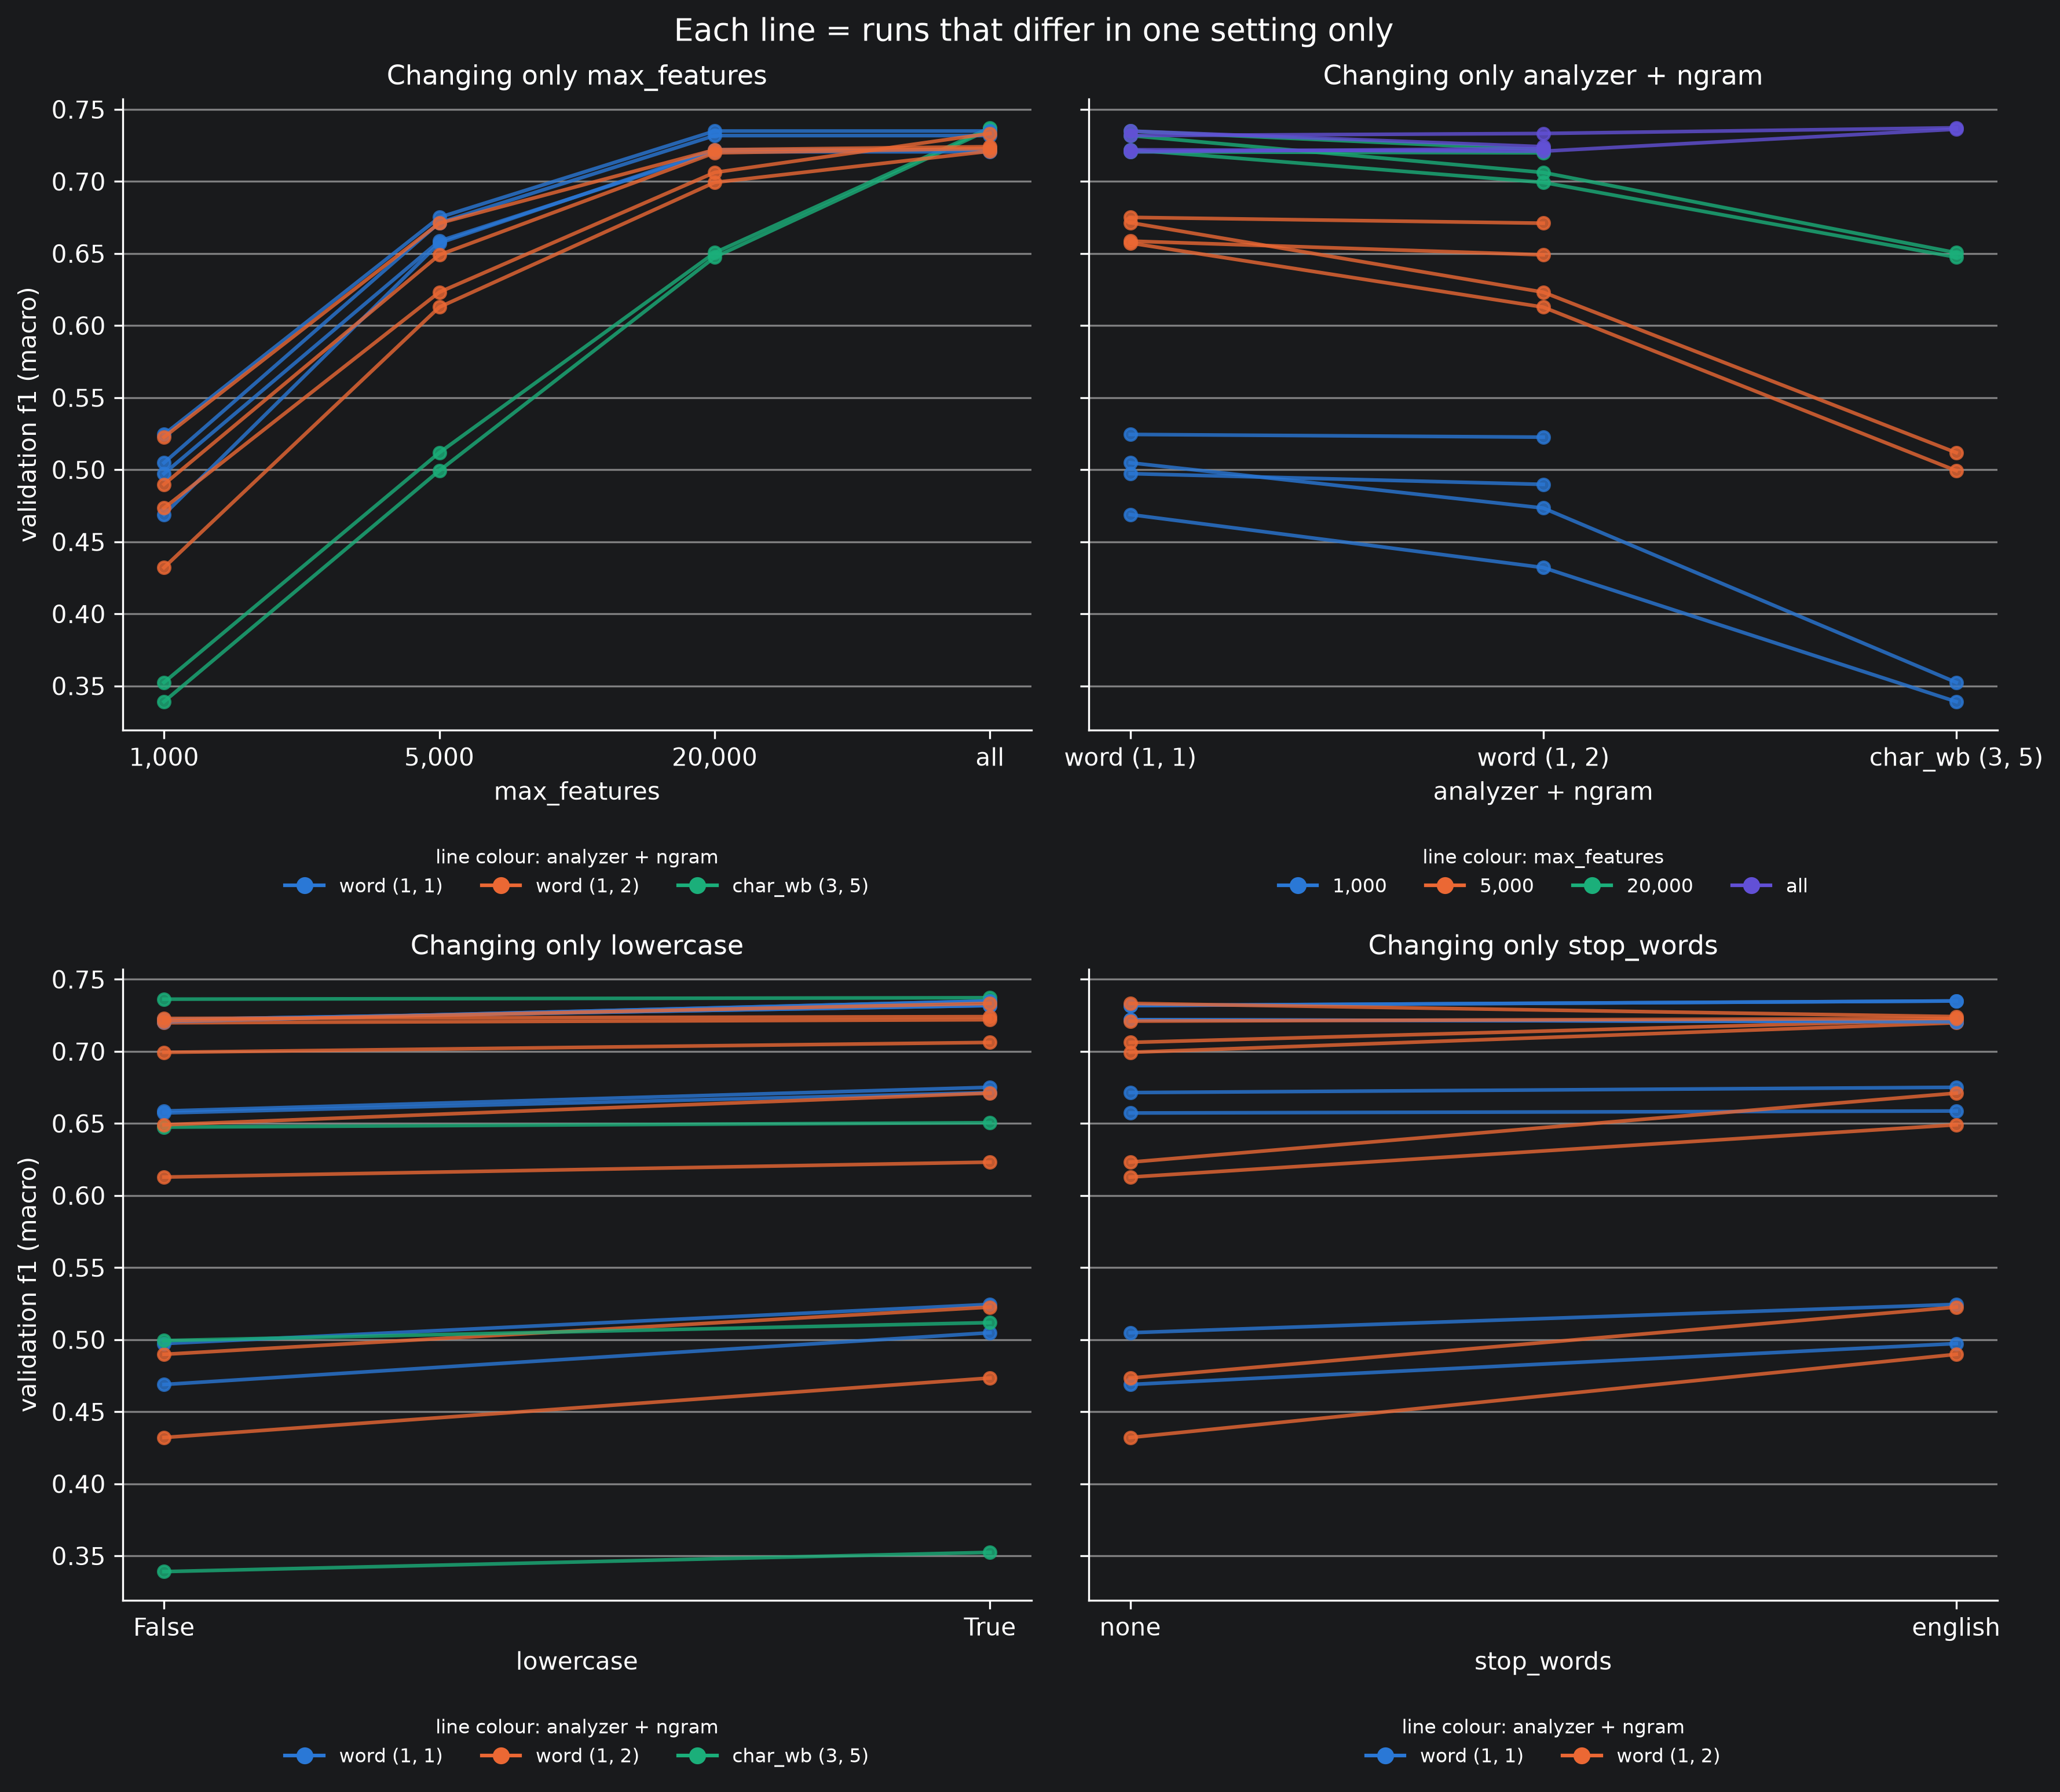

In [21]:
fig = plot_one_factor_at_a_time(grid_results, metric="f1")
fig.set_dpi(300)
fig.show

# Plot by accuracy

<bound method Figure.show of <Figure size 3600x3150 with 4 Axes>>

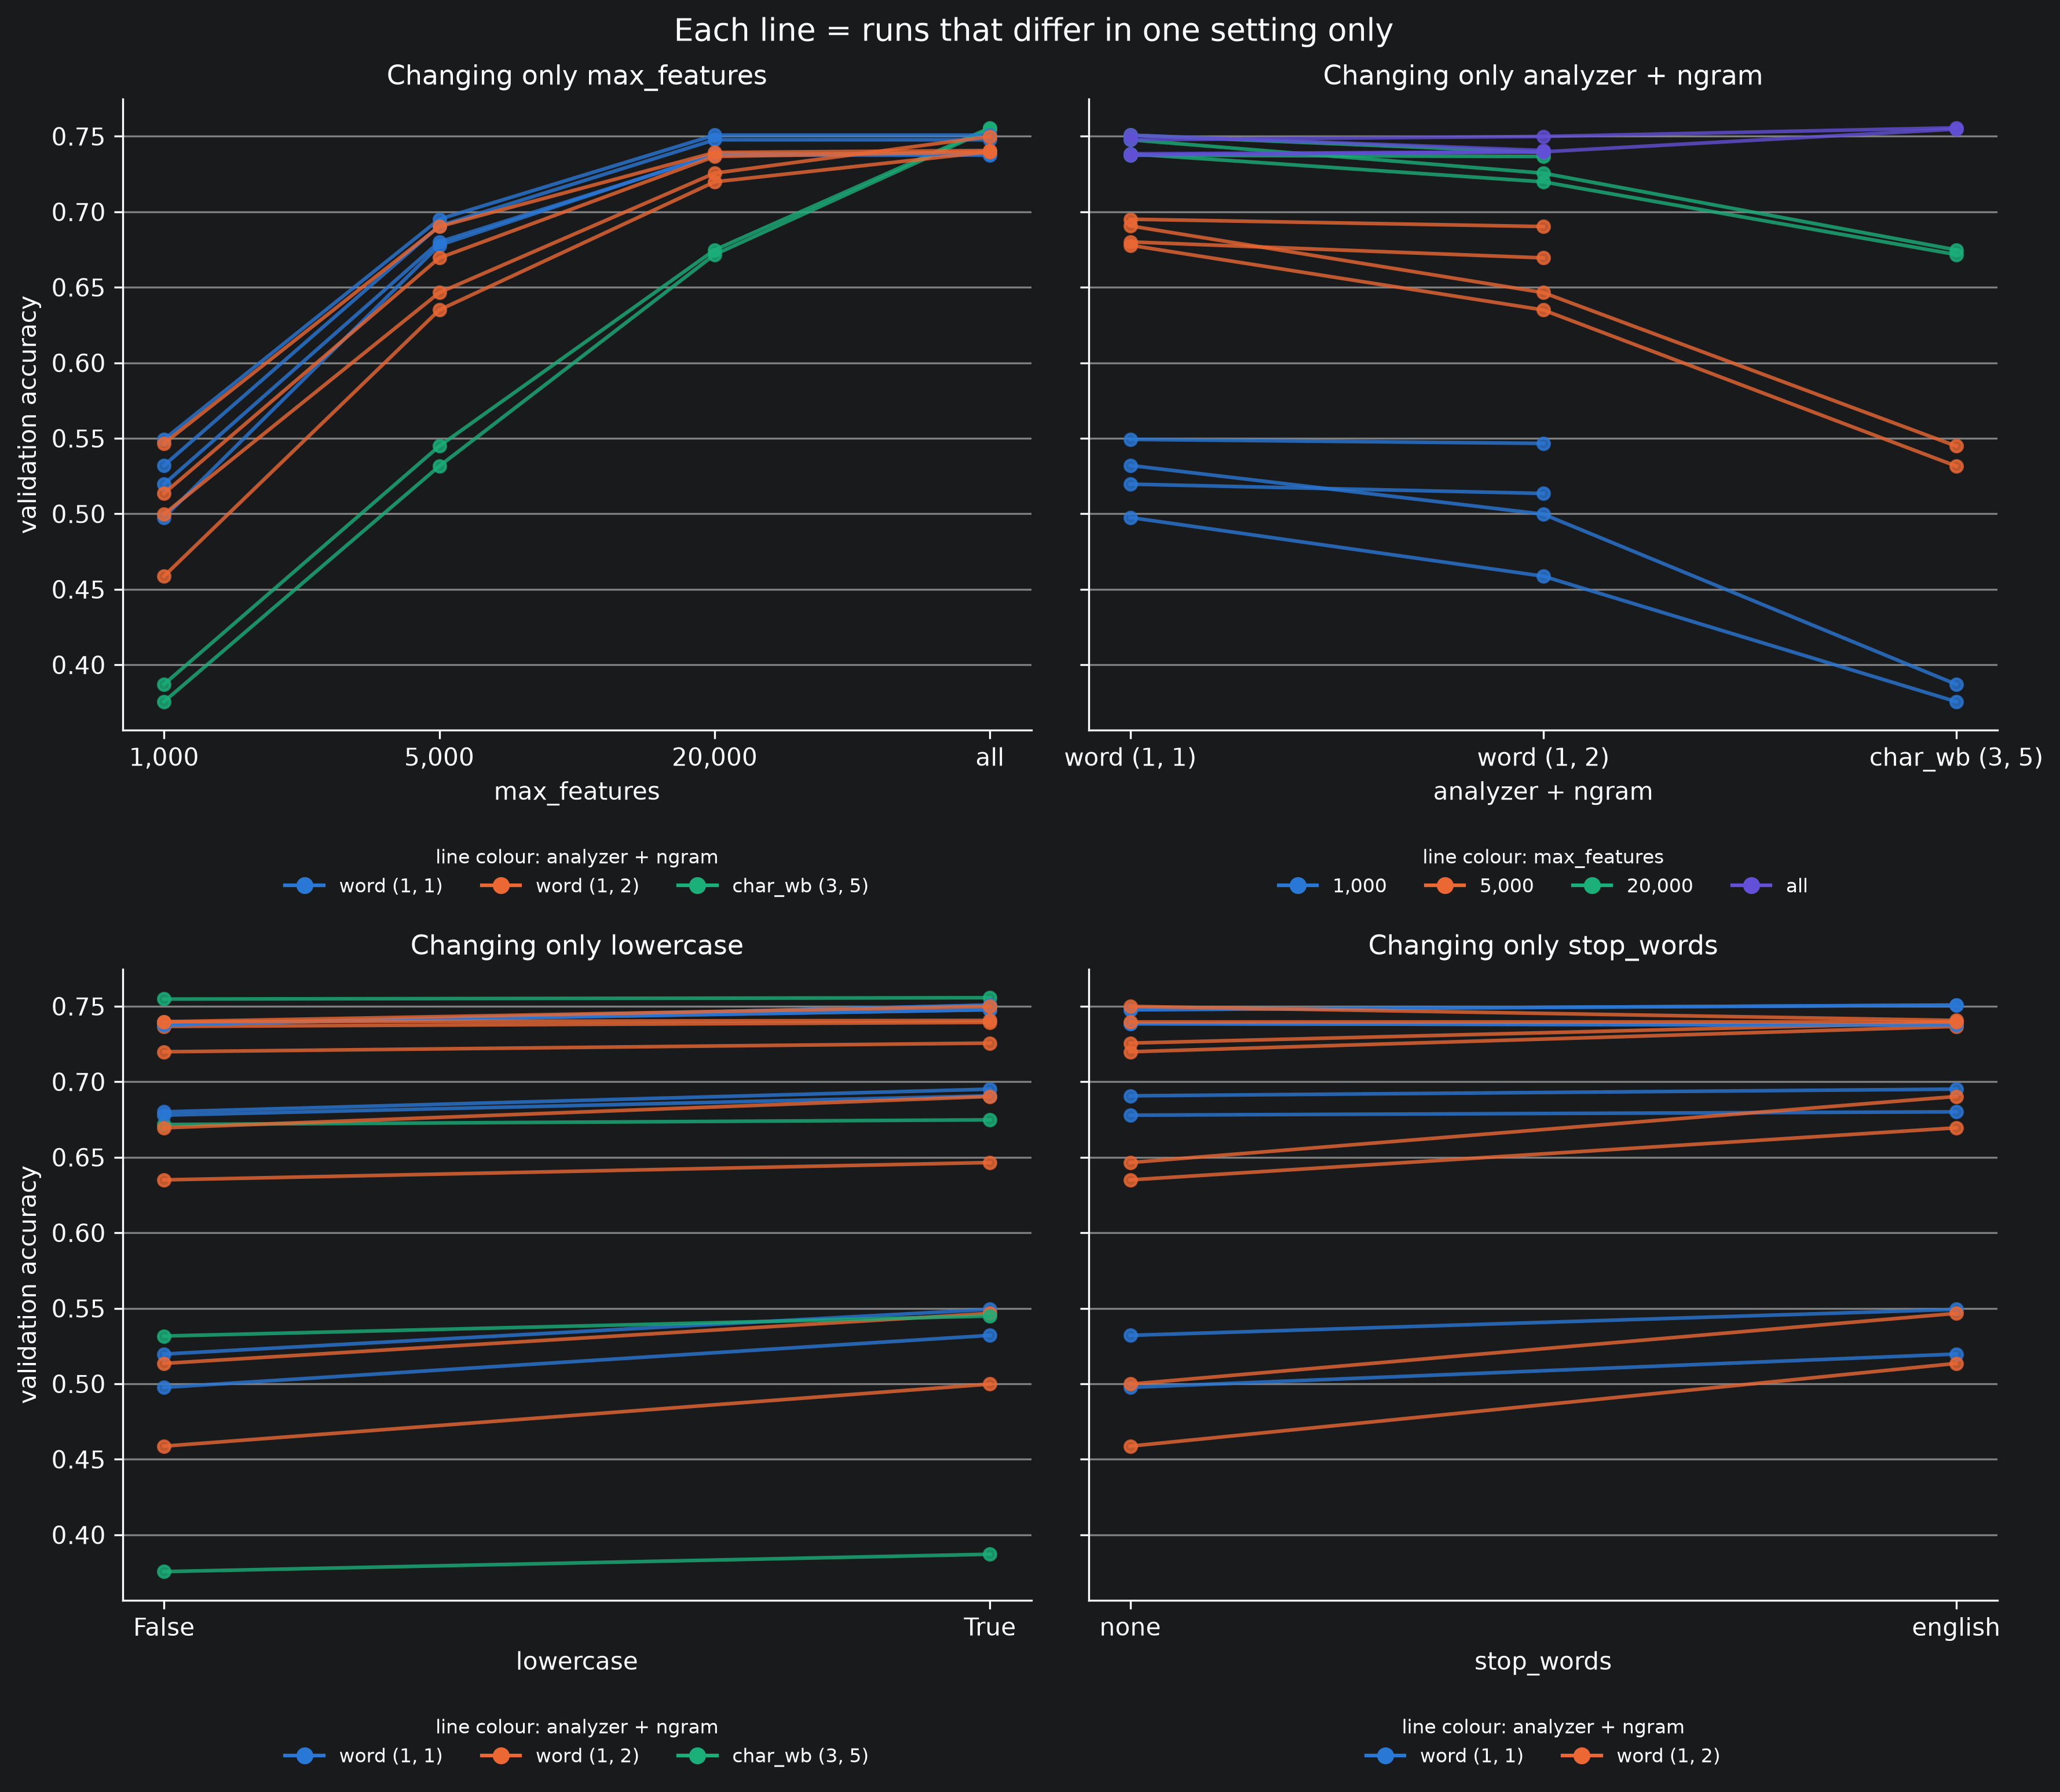

In [25]:
fig2 = plot_one_factor_at_a_time(grid_results, metric="accuracy")
fig2.set_dpi(300)
fig2.show